# The Case of the Hot Hand

Anyone who plays or watches basketball has heard of the hot hand. You might have heard
sportscasters say something like “Steph’s heating up!”, “he’s on fire!”, or even “he’s en
fuego”. You may have seen headlines such as “Warriors’ sizzling backcourt tandem sinks 72
points”. Why might that backcourt be sizzling? Well probably because Steph Curry is on
fire because he lives with a permanently hot hand. If a team has a player on the court who
suddenly gets a hot hand, typically the teammates keep feeding that player the basketball
in order to score a lot of points. Watch ESPN Sportscenter and you can occasionally see
highlights of an NBA player with a hot hand. On the other hand, if you would like to see
what a cold hand looks like, go to RIMAC and watch your professor play basketball. But,
that’s not as exciting!

In this case, we are going to think about whether or not this notion of a hot hand really exists.
Some good questions might include: what data would you need to collect to demonstrate a
hot hand exists? How would you collect that data? Would you run an experiment? What
information would be relevant? How much data would you need? In fact, there are many
questions you would have to dig into, and researchers have been doing so for decades. To
this day, the debate on the existence of the hot hand lives on.

## Regression Analysis

In order to get at that question, let’s first try to simply get familiar with basketball data
and with examining the relationships between variables found in such datasets. Load the
datafile called nba pgdata.parquet and read carefully through the data description. This
dataset has NBA player salary and performance data for the 2012/2013 NBA season. Your
job is to come up with a linear model relating variables in the dataset to player salary. In
other words, you should develop a model that you feel provides insights into what predictors
explain a player’s salary level. Further, you may have a goal to use this model to make
predictions. Below we provide some highly recommended guidance for your exploration.

### Visualization

 Make histograms of Salary, Age, FG, RB, AST, STL, BLK, and PTS.

 What do the distributions look like? Take note of any skewness. Make scatterplots of
Salary versus each of the predictors and examine the relationships.

### Histogram

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
data = pd.read_parquet("nba_pgdata.parquet")
# histogram
var = ['Salary', 'Age', 'FG', 'RB', 'AST', 'STL', 'BLK', 'PTS']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, var in zip(axes.flat, var):
    ax.hist(data[var].dropna(), bins=15, edgecolor='black')
    ax.set_title(var)
    ax.set_xlabel(var)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

The distributions of Salary, AST, and BLK are strongly right-skewed.

The disributions of FG, RB, STL, and PTS are moderately right-skewed.

The disribution of Age is sllightly right-skewed.

### Scatterplot

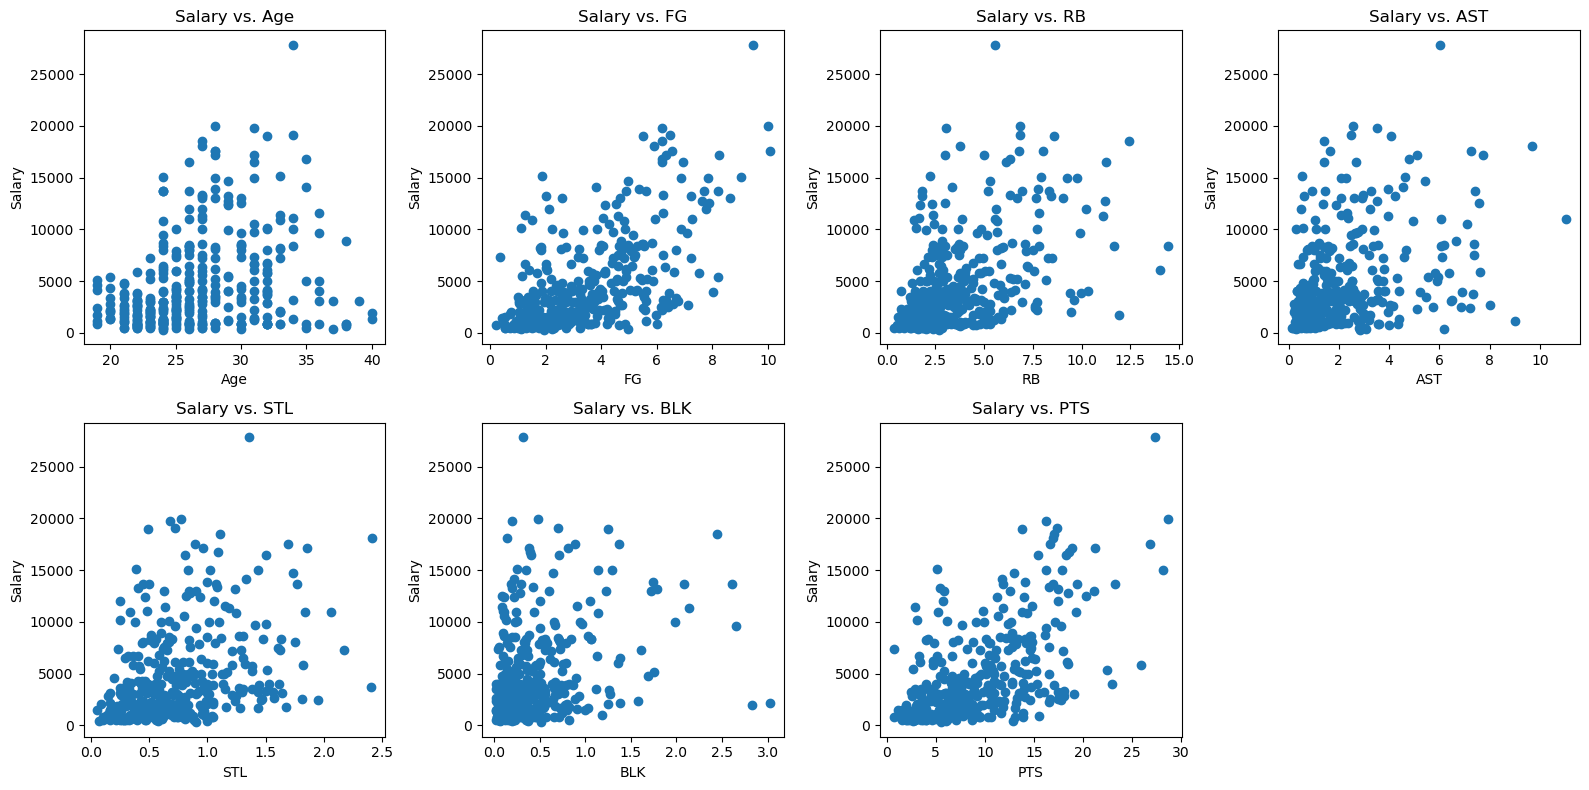

In [ ]:
pred = ['Age', 'FG', 'RB', 'AST', 'STL', 'BLK', 'PTS']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, var in zip(axes.flat, pred):
    plot_data = data[[var, 'Salary']].dropna()
    ax.scatter(plot_data[var], plot_data['Salary'])
    ax.set_title(f'Salary vs. {var}')
    ax.set_xlabel(var)
    ax.set_ylabel('Salary')

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()


FG and PTS show a strong positive linear relationship with Salary. 

AST, STL, and BLK have no clear linear relationship with Salary.

Age shows a weak positive linear relationship with Salary.

### Regression A


In [ ]:
import statsmodels.formula.api as smf

model_A = smf.ols(
    'Salary ~ Age + FG + RB + AST + STL + BLK',
    data=data
).fit()

print(model_A.summary())


                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.492
Model:                            OLS   Adj. R-squared:                  0.484
Method:                 Least Squares   F-statistic:                     58.63
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.59e-50
Time:                        19:32:58   Log-Likelihood:                -3517.9
No. Observations:                 370   AIC:                             7050.
Df Residuals:                     363   BIC:                             7077.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -8724.6669   1131.833     -7.708      0.0

**Interpret the estimated coefficients and R^2**

The coefficient on Age is 312.092, which means that one additional year in Age is associated with a $312,092 increase in Salary while holding other variables constant.

The coefficient on FG is 1156.982, which means that a one-unit increase in FG is associated with a $1,156,982 increase in salary while holding other variables constant.

The coefficient on RB is 223.312, which means that a one-unit increase in RB is associated with a $223,312 increase in salary while holding other variables constant.

The coefficient on AST is 280.498, which means that a one-unit increase in AST is associated with a $280,498 increase in salary while holding other variables constant.

The coefficient on STL is -1,064.07, which means that a one-unit increase in STL is associated with a $1,064,070 decrease in salary while holding other variables constant.

The coefficient on BLK is 1,071.1, which means that a one-unit increase in BLK is associated with a $1,071,100 increase in salary while holding other variables constant.

**Significant Variables:** Age, FG, BLK

**Insignificant Variables:** RB, AST, STL
Each independent variable is tested using a two-sided t-test. 

H0: The coefficient on each independent variable is equal to zero.

Ha: The coefficient on each independent variable is not equal to zero.

Most of the coefficient signs make sense. For example, Age, FG, and BLK have positive coefficients, which suggests that older players and players with higher FG and BLK values tend to receive higher salaries while holding other variables constant. However, it is unexpected that STL has a negative coefficient. However, STL is not statistically significant at the 5% level.

The R-squared is 0.492, which means that 49.2% of the variation in the salary can be explained by Age, FG, BLK, RB, AST, and STL.

#### Regression Plots

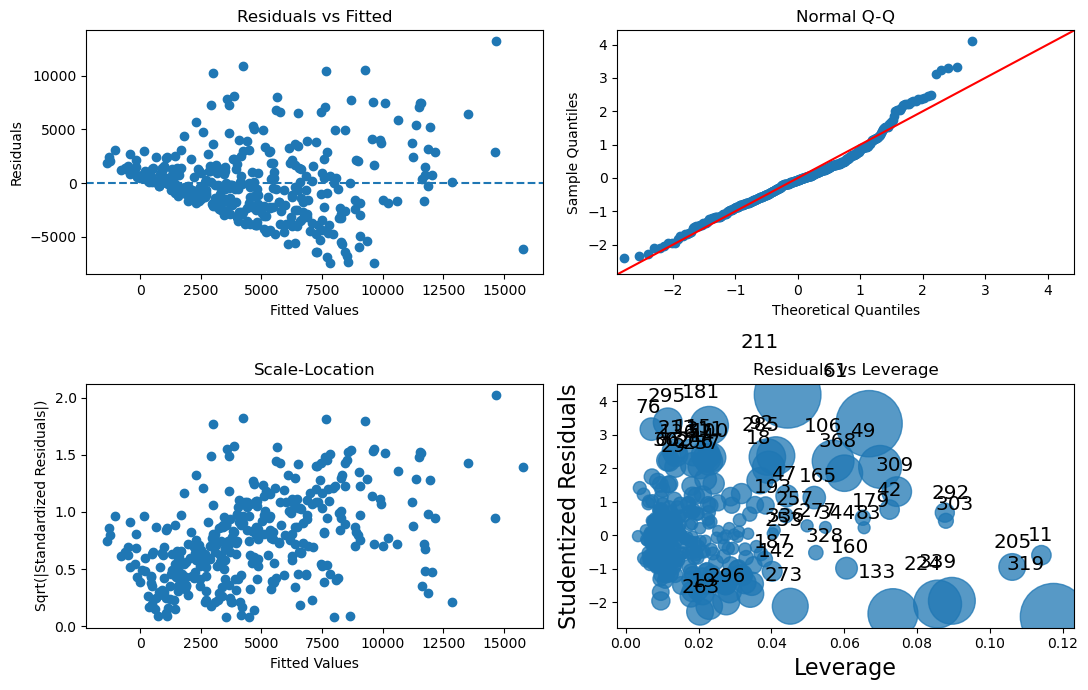

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# fitted values and residuals
fitted = model_A.fittedvalues
residuals = model_A.resid

# standardized residuals
influence = model_A.get_influence()
std_residuals = influence.resid_studentized_internal

# Residuals vs Fitted
axes[0, 0].scatter(fitted, residuals)
axes[0, 0].axhline(0, linestyle='--')
axes[0, 0].set_title('Residuals vs Fitted')
axes[0, 0].set_xlabel('Fitted Values')
axes[0, 0].set_ylabel('Residuals')

# Normal Q-Q
sm.qqplot(std_residuals, line='45', ax=axes[0, 1])
axes[0, 1].set_title('Normal Q-Q')

# Scale-Location
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_residuals)))
axes[1, 0].set_title('Scale-Location')
axes[1, 0].set_xlabel('Fitted Values')
axes[1, 0].set_ylabel('Sqrt(|Standardized Residuals|)')

# Residuals vs Leverage
sm.graphics.influence_plot(
    model_A, ax=axes[1, 1], criterion='cooks'
)
axes[1, 1].set_title('Residuals vs Leverage')

plt.tight_layout()
plt.show()


In the Residuals vs Fitted plot, the residuals show a clear fan-shaped pattern, which suggests that the error variance is not constant.

In the normal Q-Q plot,most points follow the diagonal line, but some points deviate from the line, which suggests that the residuals are not normally distributed.

The points in the scale-location plot show an upward trend, which suggests heteroskedasticity.

Residuals vs. Leverage plot shows that some observations have relatively high leverage and large Cook's distance values. These observations may strongly influence the regression results. 

### Regression B

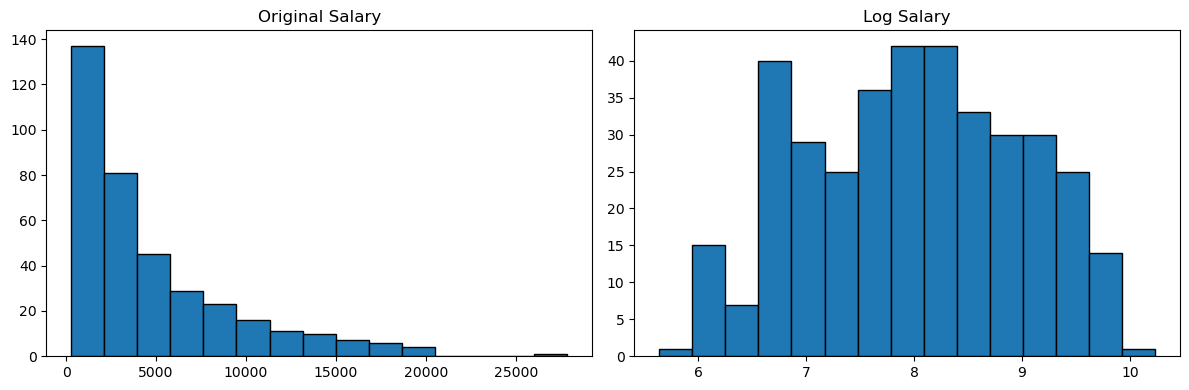

In [ ]:
data['log_Salary'] = np.log(data['Salary'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(data['Salary'].dropna(), bins=15, edgecolor='black')
axes[0].set_title('Original Salary')

axes[1].hist(data['log_Salary'].dropna(), bins=15, edgecolor='black')
axes[1].set_title('Log Salary')

plt.tight_layout()
plt.show()

log_Salary is approximately normally distributed, which suggests that log transformation can significant reduce the influence of outliers. 

In [ ]:
model_B = smf.ols(
    'log_Salary ~ Age + FG + RB + AST + STL + BLK',
    data=data
).fit()

print(model_B.summary())

                            OLS Regression Results                            
Dep. Variable:             log_Salary   R-squared:                       0.455
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     50.60
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           4.35e-45
Time:                        20:07:20   Log-Likelihood:                -410.42
No. Observations:                 370   AIC:                             834.8
Df Residuals:                     363   BIC:                             862.2
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.3022      0.255     20.803      0.0

**Interpretation of Coefficients**

The coefficient on Age is 0.0577, which means that one additional year of age is associated with a 5.94% increase in salary while holding other variables constant.

The coefficient on FG is 0.2077, which means that a one-unit increase in FG is associated with a 23.08% increase in salary while holding other variables constant.

The coefficient on RB is 0.0667, which means that a one-unit increase in RB is associated with a 6.90% increase in salary while holding other variables constant.

The coefficient on AST is 0.0463, which means that a one-unit increase in AST is associated with a 4.74% increase in salary while holding other variables constant.

The coefficient on STL is 0.0017, which means that a one-unit increase in STL is associated with a 0.17% increase in salary while holding other variables constant.

The coefficient on BLK is 0.2104, which means that a one-unit increase in BLK is associated with a 23.42% increase in salary while holding other variables constant.


**Significant Variables:** Age, FG, RB

**Insignificant Variables:** BLK, AST, STL

The R-squared is 0.455, which means that 45.5% of the variation in the salary can be explained by Age, FG, BLK, RB, AST, and STL.

#### Regression Plots

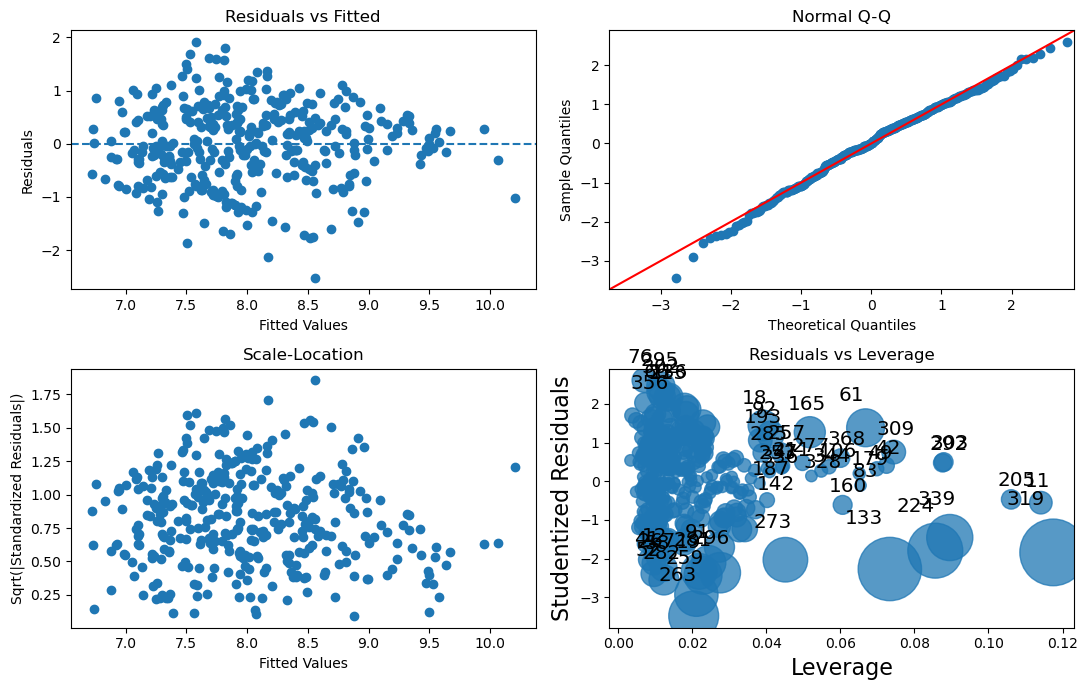

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# fitted values and residuals
fitted = model_B.fittedvalues
residuals = model_B.resid

# standardized residuals
influence = model_B.get_influence()
std_residuals = influence.resid_studentized_internal

# Residuals vs Fitted
axes[0, 0].scatter(fitted, residuals)
axes[0, 0].axhline(0, linestyle='--')
axes[0, 0].set_title('Residuals vs Fitted')
axes[0, 0].set_xlabel('Fitted Values')
axes[0, 0].set_ylabel('Residuals')

# Normal Q-Q
sm.qqplot(std_residuals, line='45', ax=axes[0, 1])
axes[0, 1].set_title('Normal Q-Q')

# Scale-Location
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_residuals)))
axes[1, 0].set_title('Scale-Location')
axes[1, 0].set_xlabel('Fitted Values')
axes[1, 0].set_ylabel('Sqrt(|Standardized Residuals|)')

# Residuals vs Leverage
sm.graphics.influence_plot(
    model_B, ax=axes[1, 1], criterion='cooks'
)
axes[1, 1].set_title('Residuals vs Leverage')

plt.tight_layout()
plt.show()

The diagnostic plots suggest that Model B performs better than Model A. The log transformation improves the normality of the residuals and reduces the heteroskedasticity problem. However, some potentially influential observations remain.

### Regression C

In [ ]:
model_C = smf.ols(
    'log_Salary ~ Age + FG + RB + AST + STL + BLK + PTS',
    data=data
).fit()

print(model_C.summary())

                            OLS Regression Results                            
Dep. Variable:             log_Salary   R-squared:                       0.465
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                     45.01
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.23e-45
Time:                        20:18:50   Log-Likelihood:                -407.01
No. Observations:                 370   AIC:                             830.0
Df Residuals:                     362   BIC:                             861.3
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.2968      0.253     20.944      0.0

When PTS is included in the model, the coefficient on FG(p=0.368) becomes negative and insignificant. BLK(p=0.032) becomes one significant predictor, and the added PTS(0.01) is also one significant predictor. This may be caused by multicollinearity between FG and PTS. The two variables may share similar information because they are related to scoring performance.

### Regression D

In [ ]:
from sklearn.preprocessing import StandardScaler

df = data.copy()

df[['log_Salary', 'Age', 'RB', 'AST', 'STL', 'BLK', 'PTS']] = StandardScaler().fit_transform(
    df[['log_Salary', 'Age', 'RB', 'AST', 'STL', 'BLK', 'PTS']]
)

model_D = smf.ols(
    'log_Salary ~ Age + RB + AST + STL + BLK + PTS',
    data=df
).fit()

print(model_D.summary())

                            OLS Regression Results                            
Dep. Variable:             log_Salary   R-squared:                       0.464
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                     52.41
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           2.41e-46
Time:                        20:32:12   Log-Likelihood:                -409.58
No. Observations:                 370   AIC:                             833.2
Df Residuals:                     363   BIC:                             860.6
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -7.656e-17      0.038  -1.99e-15      1.0

Standardized coefficients allow us to directly compare the strength of the relationships between different independent variables and the dependent variable. This is because all variables are measured on the same standardized scale.

For example, PTS has a standardized coefficient of 0.4279, which means that a one-standard-deviation increase in PTS is associated with a 0.4279 standard-deviation increase in log Salary while holding other variables constant. The coefficient on Age is 0.2537, which means that a one-standard-deviation increase in Age is associated with a 0.2537 standard-deviation increase in log Salary while holding other variables constant. Therefore, PTS has a stronger positive relationship with log Salary than Age.


## Hot Hand Hypothesis Testing

### Conditional Probability Approach


In [ ]:
shooting_table = pd.DataFrame({
    'Player': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I'],
    'prob_hit_after_miss': [0.56, 0.51, 0.46, 0.60, 0.47, 0.51, 0.58, 0.52, 0.71],
    'prob_hit_overall': [0.50, 0.52, 0.46, 0.56, 0.47, 0.46, 0.54, 0.52, 0.62],
    'prob_hit_after_hit': [0.49, 0.53, 0.46, 0.55, 0.45, 0.43, 0.53, 0.51, 0.57],
})

shooting_table['diff_after_hit_minus_after_miss'] = (
    shooting_table['prob_hit_after_hit'] - shooting_table['prob_hit_after_miss']
)

print(shooting_table)